# Analyst Adjustments for Comparability: LIFO Reserves, Operating Leases, Pension Deficits and Deferred Taxes from SEC Filings, How They Change Leverage, Coverage and Synthetic Ratings, and Whether Adjusted Ratios Explain Risk Better

Reported ratios are not comparable across companies, because accounting choices and standards move items on and off the balance sheet. The CFA curriculum's financial-statement-analysis readings ask the analyst to **adjust** them before comparing:

- **LIFO reserve:** a company using LIFO reports inventory at old costs. Adding the reserve converts inventory (and, after tax, equity) to FIFO, and the change in the reserve converts cost of sales.
- **Operating leases:** since ASC 842 (2019) operating lease liabilities are on U.S. balance sheets, but outside reported "debt". Rating agencies add them to debt, add the lease cost back to EBITDA and treat the interest part of the lease cost as interest.
- **Pension deficits:** an underfunded defined-benefit plan is a debt-like obligation; agencies add the after-tax deficit to debt.
- **Deferred tax liabilities:** when they are not expected to reverse (a growing company keeps investing), many analysts treat them as equity rather than as liabilities.

This notebook applies the four adjustments to every U.S. listed company that reports the relevant XBRL items for fiscal 2019–2025, and measures:

1. How much the adjustments change leverage, coverage and returns, and in which industries.
2. How much they **reshuffle rankings** and synthetic credit ratings (interest coverage mapped to ratings with Damodaran's table).
3. Whether adjusted leverage is the **better risk measure**: does it explain the next year's equity volatility better than reported leverage, in a regression and in LightGBM?

**Data.** SEC XBRL frames API (debt, operating lease liabilities, cost and discount rates, LIFO reserves, pension funded status, deferred taxes, EBIT, depreciation, interest, equity, assets, revenue, cost of sales, taxes; 2019–2025); SEC Financial Statement Data Sets (industry codes); Damodaran Online (interest coverage to rating table); Yahoo Finance (monthly prices).

**Methods.** LIFO-to-FIFO conversion, lease capitalisation with interest and depreciation split, pension and deferred-tax adjustments, leverage and coverage ratios, synthetic ratings, Spearman rank changes, OLS and LightGBM with grouped cross-validation.

**Key output.** Reported vs adjusted ratios by industry; the companies most changed by each adjustment; rating migrations; and whether the adjustments improve the explanation of risk.

## 1. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import io
import zipfile
import lightgbm as lgb
import yfinance as yf
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
rng = np.random.default_rng(SEED)
SEC_HEADERS = {"User-Agent": os.getenv("SEC_USER_AGENT", "").strip()}
if not SEC_HEADERS["User-Agent"]:
    raise RuntimeError(
        "SEC_USER_AGENT missing in .env (the SEC asks automated clients to"
        " identify themselves)."
    )
FIRST_CY, LAST_CY = 2019, 2025
CONCEPTS = {
    "rev": (
        ["Revenues", "RevenueFromContractWithCustomerExcludingAssessedTax"],
        "USD",
        "D",
    ),
    "cogs": (["CostOfRevenue", "CostOfGoodsAndServicesSold"], "USD", "D"),
    "ebit": (["OperatingIncomeLoss"], "USD", "D"),
    "da": (
        [
            "DepreciationDepletionAndAmortization",
            "DepreciationAndAmortization",
        ],
        "USD",
        "D",
    ),
    "interest": (
        [
            "InterestExpense",
            "InterestExpenseNonoperating",
            "InterestExpenseDebt",
            "InterestAndDebtExpense",
        ],
        "USD",
        "D",
    ),
    "pretax": (
        [
            "IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest"
        ],
        "USD",
        "D",
    ),
    "tax": (["IncomeTaxExpenseBenefit"], "USD", "D"),
    "ni": (["NetIncomeLoss"], "USD", "D"),
    "lease_cost": (["OperatingLeaseCost"], "USD", "D"),
    "ltd": (["LongTermDebt", "LongTermDebtNoncurrent"], "USD", "I"),
    "st_debt": (["ShortTermBorrowings", "DebtCurrent"], "USD", "I"),
    "lease_liab": (["OperatingLeaseLiability"], "USD", "I"),
    "lease_rate": (
        ["OperatingLeaseWeightedAverageDiscountRatePercent"],
        "pure",
        "I",
    ),
    "lifo": (["InventoryLIFOReserve"], "USD", "I"),
    "pension": (["DefinedBenefitPlanFundedStatusOfPlan"], "USD", "I"),
    "dtl": (["DeferredIncomeTaxLiabilitiesNet"], "USD", "I"),
    "inv": (["InventoryNet"], "USD", "I"),
    "eq": (["StockholdersEquity"], "USD", "I"),
    "assets": (["Assets"], "USD", "I"),
    "cash": (["CashAndCashEquivalentsAtCarryingValue"], "USD", "I"),
}
MIN_REV = 250e6
DAMODARAN = "https://pages.stern.nyu.edu/~adamodar/pc/datasets/"

print(
    f"lightgbm {lgb.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · yfinance 1.7.0 · run on 2026-11-12


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 2. Data

Annual flows and year-end balances for fiscal 2019–2025 from the XBRL frames; industry codes from the Financial Statement Data Sets. Financial companies (SIC 6000–6799) are excluded because debt is their raw material.

In [3]:
def sec_get(url):
    for attempt in range(4):
        r = requests.get(url, headers=SEC_HEADERS, timeout=600)
        if r.status_code == 200:
            return r
        if r.status_code == 404:
            return None
        time.sleep(2 + 3 * attempt)
    r.raise_for_status()


def fetch_frames():
    out = []
    for item, (tags, unit, ptype) in CONCEPTS.items():
        for rank, tag in enumerate(tags):
            for cy in range(FIRST_CY - 1, LAST_CY + 1):
                r = sec_get(
                    f"https://data.sec.gov/api/xbrl/frames/us-gaap/{tag}/{unit}/CY{cy}{'Q4I' if ptype == 'I' else ''}.json"
                )
                if r is None:
                    continue
                out.append(
                    pd.DataFrame(r.json()["data"])[
                        ["cik", "entityName", "val"]
                    ].assign(item=item, cy=cy, rank=rank)
                )
                time.sleep(0.12)
    return pd.concat(out, ignore_index=True)


def fetch_sic():
    out = []
    for q in ["2025q1", "2023q1", "2021q1"]:
        z = zipfile.ZipFile(
            io.BytesIO(
                sec_get(
                    f"https://www.sec.gov/files/dera/data/financial-statement-data-sets/{q}.zip"
                ).content
            )
        )
        out.append(
            pd.read_csv(
                z.open("sub.txt"), sep="\t", dtype=str, usecols=["cik", "sic"]
            )
        )
    return (
        pd.concat(out)
        .dropna()
        .drop_duplicates("cik")
        .astype({"cik": int, "sic": int})
    )


def fetch_ratings():
    x = pd.read_excel(
        io.BytesIO(
            requests.get(DAMODARAN + "ratings.xls", timeout=120).content
        ),
        sheet_name=0,
        header=None,
    ).iloc[18:33, :4]
    x.columns = ["low", "high", "rating", "spread"]
    return x.dropna().astype({"low": float, "high": float, "spread": float})


t0 = time.time()
FR = cached("sec_frames_adjustments", fetch_frames, max_age_hours=24 * 7)
SIC = cached("fsds_sic_codes", fetch_sic, max_age_hours=24 * 90)
RAT = cached(
    "damodaran_coverage_ratings", fetch_ratings, max_age_hours=24 * 90
)
FR = FR.sort_values("rank").drop_duplicates(["cik", "item", "cy"])
A = (
    FR.pivot_table(index=["cik", "cy"], columns="item", values="val")
    .reset_index()
    .merge(SIC, on="cik", how="left")
)
names = FR.drop_duplicates("cik").set_index("cik").entityName
A = A.sort_values(["cik", "cy"])
A["lifo_prev"] = (
    A.groupby("cik").lifo.shift(1).where(A.groupby("cik").cy.diff() == 1)
)
A = A[
    (A.cy >= FIRST_CY)
    & (A.rev > MIN_REV)
    & A.ebit.notna()
    & A["eq"].notna()
    & A.assets.notna()
    & ~A.sic.between(6000, 6799)
].copy()
# interest stays missing when not reported
for c in [
    "ltd",
    "st_debt",
    "lease_liab",
    "lifo",
    "dtl",
    "lease_cost",
    "da",
    "cash",
]:
    A[c] = A[c].fillna(0)
A["pension_deficit"] = (-A.pension).clip(lower=0).fillna(0)
cover = {
    "operating leases": (A.lease_liab > 0).mean(),
    "LIFO reserve": (A.lifo > 0).mean(),
    "pension deficit": (A.pension_deficit > 0).mean(),
    "net deferred tax liability": (A.dtl > 0).mean(),
}
print(
    f"{len(A):,} company-years, {A.cik.nunique():,} non-financial companies"
    f" with revenue above USD 250 m · {time.time() - t0:.0f} s"
)
print(
    "Share of company-years with each item: "
    + ", ".join(f"{k} {v:.0%}" for k, v in cover.items())
)

12,115 company-years, 2,403 non-financial companies with revenue above USD 250 m · 0 s
Share of company-years with each item: operating leases 82%, LIFO reserve 4%, pension deficit 5%, net deferred tax liability 63%


## 3. The adjustments

With *t* the effective tax rate (clipped to 0–35%, 21% when unavailable) and *r* the reported weighted-average discount rate on operating leases:

| Item | Reported | Adjusted |
|---|---|---|
| Debt | long-term + short-term debt | + operating lease liability + pension deficit × (1 − *t*) |
| EBITDA | EBIT + D&A | + operating lease cost |
| EBIT | EBIT | + lease interest (*r* × lease liability) |
| Interest | interest expense | + lease interest |
| Inventory, equity | as reported | + LIFO reserve (equity + reserve × (1 − *t*)) |
| Equity | as reported | + net deferred tax liability; − pension deficit × (1 − *t*) |
| EBIT (LIFO) | — | + change in LIFO reserve |

In [4]:
A["t"] = (A.tax / A.pretax).where(A.pretax > 0).clip(0, 0.35).fillna(0.21)
A["r_lease"] = (A.lease_rate.fillna(A.lease_rate.median())).clip(0.01, 0.15)
A["debt_rep"] = A.ltd + A.st_debt
A["ebitda_rep"] = A.ebit + A.da
A["lease_int"] = A.r_lease * A.lease_liab
A["debt_adj"] = A.debt_rep + A.lease_liab + A.pension_deficit * (1 - A.t)
A["ebitda_adj"] = A.ebitda_rep + A.lease_cost
A["ebit_adj"] = A.ebit + A.lease_int + (A.lifo - A.lifo_prev.fillna(A.lifo))
# coverage only where interest expense is reported
A["int_adj"] = (A.interest + A.lease_int).where(A.interest > 0)
A["eq_adj"] = (
    A["eq"] + A.lifo * (1 - A.t) + A.dtl - A.pension_deficit * (1 - A.t)
)
A["assets_adj"] = A.assets + A.lifo
A["cap_rep"], A["cap_adj"] = A.debt_rep + A["eq"], A.debt_adj + A.eq_adj
A["ni_adj"] = A.ni + (A.ebit_adj - A.ebit - A.lease_int) * (1 - A.t)
RATIOS = {
    "debt / EBITDA": ("debt_rep", "ebitda_rep", "debt_adj", "ebitda_adj"),
    "debt / capital": ("debt_rep", "cap_rep", "debt_adj", "cap_adj"),
    "interest cover": ("ebit", "interest", "ebit_adj", "int_adj"),
    "return on equity": ("ni", "eq", "ni_adj", "eq_adj"),
}
for k, (n1, d1, n2, d2) in RATIOS.items():
    A[f"{k} | reported"] = (A[n1] / A[d1]).where(A[d1] > 0)
    A[f"{k} | adjusted"] = (A[n2] / A[d2]).where(A[d2] > 0)
A["interest cover | reported"] = A["interest cover | reported"].clip(-20, 100)
A["interest cover | adjusted"] = A["interest cover | adjusted"].clip(-20, 100)
# latest complete fiscal year
L = A[A.cy == A.cy.max() - 1].copy()
SUMM = pd.DataFrame({
    k: {
        "median reported": L[f"{k} | reported"].median(),
        "median adjusted": L[f"{k} | adjusted"].median(),
        "Spearman rank correlation": (
            L[[f"{k} | reported", f"{k} | adjusted"]]
            .corr("spearman")
            .iloc[0, 1]
        ),
        "companies moving 10+ percentiles": (
            (
                L[f"{k} | reported"].rank(pct=True)
                - L[f"{k} | adjusted"].rank(pct=True)
            )
            .abs()
            .gt(0.10)
            .mean()
        ),
    }
    for k in RATIOS
}).T
SHARE = (
    pd.Series({
        "operating leases": L.lease_liab.sum(),
        "pension deficits (after tax)": (L.pension_deficit * (1 - L.t)).sum(),
    })
    / L.debt_rep.sum()
)
print(
    f"Fiscal {L.cy.iloc[0]}, {len(L):,} companies · debt added: operating"
    f" leases {SHARE.iloc[0]:.1%} of reported debt, pension deficits"
    f" {SHARE.iloc[1]:.1%}; LIFO reserves USD {L.lifo.sum() / 1e9:,.0f} bn;"
    " net deferred tax liabilities reclassified to equity USD"
    f" {L.dtl.sum() / 1e9:,.0f} bn"
)
SUMM.round(3)

Fiscal 2024, 1,728 companies · debt added: operating leases 17.1% of reported debt, pension deficits 0.1%; LIFO reserves USD 15 bn; net deferred tax liabilities reclassified to equity USD 521 bn


,median reported,median adjusted,Spearman rank correlation,companies moving 10+ percentiles
debt / EBITDA,1.71,2.12,0.92,0.19
debt / capital,0.28,0.34,0.90,0.21
interest cover,3.15,2.97,0.98,0.02
return on equity,0.08,0.08,1.00,0.01


In [5]:
SECTORS = {
    (2000, 2099): "Food and beverages",
    (2800, 2899): "Chemicals and pharmaceuticals",
    (2900, 2999): "Petroleum refining",
    (3000, 3999): "Other manufacturing",
    (4000, 4799): "Transportation",
    (4800, 4899): "Telecommunications",
    (4900, 4999): "Utilities",
    (5000, 5199): "Wholesale",
    (5200, 5999): "Retail",
    (5800, 5899): "Restaurants",
    (7000, 7099): "Hotels",
    (7300, 7399): "Software and services",
    (8000, 8099): "Health care services",
    (1000, 1499): "Mining, oil and gas",
}
L["sector"] = L.sic.map(
    lambda s: next(
        (
            v
            for (lo, hi), v in sorted(
                SECTORS.items(), key=lambda kv: kv[0][1] - kv[0][0]
            )
            if pd.notna(s) and lo <= s <= hi
        ),
        "Other",
    )
)
BYS = L.groupby("sector").agg(
    companies=("cik", "size"),
    debt_EBITDA_reported=("debt / EBITDA | reported", "median"),
    debt_EBITDA_adjusted=("debt / EBITDA | adjusted", "median"),
    lease_share_of_adjusted_debt=(
        "lease_liab",
        lambda v: v.sum() / L.loc[v.index, "debt_adj"].sum(),
    ),
    LIFO_users=("lifo", lambda v: (v > 0).mean()),
)
BYS = BYS[BYS.companies >= 20].sort_values(
    "lease_share_of_adjusted_debt", ascending=False
)
print(
    "Median debt / EBITDA by sector, reported and adjusted, and the share of"
    " adjusted debt that is operating leases"
)
BYS.round(2)

Median debt / EBITDA by sector, reported and adjusted, and the share of adjusted debt that is operating leases


,companies,debt_EBITDA_reported,debt_EBITDA_adjusted,lease_share_of_adjusted_debt,LIFO_users
sector,,,,,
Retail,104,0.54,2.18,0.42,0.05
Hotels,23,3.41,4.51,0.39,0.00
Restaurants,35,2.28,4.29,0.27,0.00
Health care services,43,1.81,2.30,0.23,0.00
Transportation,62,1.80,2.14,0.20,0.00
Software and services,308,1.03,1.66,0.18,0.00
Telecommunications,40,4.07,4.33,0.15,0.00
Other,278,1.55,1.90,0.14,0.04
Wholesale,57,1.58,1.97,0.13,0.12


In [6]:
def top(col, n=6, extra=()):
    d = (
        L[L[col] > 0]
        .assign(company=lambda x: x.cik.map(names))
        .sort_values(col, ascending=False)
        .head(n)
    )
    return d[["company", col, "debt_rep", "eq", *extra]].assign(
        **{c: (d[c] / 1e9).round(1) for c in [col, "debt_rep", "eq"]}
    )


print("Largest operating lease liabilities (USD bn)")
display(
    top(
        "lease_liab",
        extra=("debt / EBITDA | reported", "debt / EBITDA | adjusted"),
    ).round(2)
)
print("Largest LIFO reserves (USD bn)")
display(
    top("lifo", extra=("inv",)).assign(inv=lambda d: (d.inv / 1e9).round(1))
)
print("Largest pension deficits (USD bn)")
top(
    "pension_deficit",
    extra=("debt / capital | reported", "debt / capital | adjusted"),
).round(2)

Largest operating lease liabilities (USD bn)


,company,lease_liab,debt_rep,eq,debt / EBITDA | reported,debt / EBITDA | adjusted
13844,"AMAZON.COM, INC.",79.60,58.20,286.00,0.48,1.03
20840,"T-MOBILE US, INC.",29.70,82.30,61.70,2.66,3.14
7206,MGM Resorts International,25.20,6.40,3.00,2.74,6.82
7190,MICROSOFT CORPORATION,21.90,45.00,302.70,0.41,0.59
28940,"BWX TECHNOLOGIES, INC.",21.10,1.00,1.10,2.24,47.44
22303,"Meta Platforms, Inc.",20.20,28.80,182.60,0.34,0.56


Largest LIFO reserves (USD bn)


,company,lifo,debt_rep,eq,inv
4439,DEERE & CO,2.90,12.80,22.50,7.70
2032,THE KROGER CO.,2.40,15.90,8.30,NaN
29080,LYONDELLBASELL INDUSTRIES N.V.,1.30,0.10,12.50,4.70
1094,DOLLAR GENERAL CORPORATION,0.90,0.00,7.40,6.70
4259,"W.W. Grainger, Inc.",0.80,2.80,3.40,2.30
38440,US FOODS HOLDING CORP.,0.50,0.00,4.50,1.60


Largest pension deficits (USD bn)


,company,pension_deficit,debt_rep,eq,debt / capital | reported,debt / capital | adjusted
1861,INTEL CORPORATION,0.50,53.70,99.30,0.35,0.35
2518,TENET HEALTHCARE CORP,0.30,0.00,4.20,0.00,0.25
44770,OTIS WORLDWIDE CORPORATION,0.30,8.30,-4.80,2.39,2.20
3276,"SMITHFIELD FOODS, INC.",0.30,2.00,5.80,0.25,0.29
8097,DENTSPLY SIRONA Inc.,0.30,2.30,1.90,0.54,0.59
20840,"T-MOBILE US, INC.",0.30,82.30,61.70,0.57,0.59


## 4. Synthetic ratings

Damodaran maps interest coverage to a bond rating (for large non-financial companies). The rating is computed from reported and from adjusted coverage, for companies that report interest expense. Adding the same lease interest to EBIT and to interest pulls coverage towards one: it lowers it for companies covering their interest more than once.

In [7]:
RAT = RAT.sort_values("low")
ORDER = list(RAT.sort_values("low", ascending=False).rating)


def rating(c):
    c = np.asarray(c, dtype=float)
    out = np.full(len(c), ORDER[-1], dtype=object)
    for _, r in RAT.iterrows():
        out[(c >= r.low) & (c < r.high)] = r.rating
    out[c >= RAT.high.max()] = ORDER[0]
    return out


L = L[
    L["interest cover | reported"].notna()
    & L["interest cover | adjusted"].notna()
].copy()
L["rating | reported"] = rating(L["interest cover | reported"])
L["rating | adjusted"] = rating(L["interest cover | adjusted"])
pos = {r: i for i, r in enumerate(ORDER)}
L["notches"] = L["rating | adjusted"].map(pos) - L["rating | reported"].map(
    pos
)
MIG = pd.crosstab(L["rating | reported"], L["rating | adjusted"]).reindex(
    index=ORDER, columns=ORDER, fill_value=0
)
BBB = next(r for r in ORDER if "BBB" in r)
ig = lambda r: pos[r] <= pos[BBB]
fallen = (
    L["rating | reported"].map(ig) & ~L["rating | adjusted"].map(ig)
).sum()
print(
    f"Synthetic ratings: unchanged {(L.notches == 0).mean():.0%}, lower"
    f" {(L.notches > 0).mean():.0%} (median"
    f" {L.notches[L.notches > 0].median():.0f} notches), higher"
    f" {(L.notches < 0).mean():.0%}; investment grade to high yield: {fallen}"
    " companies"
)
MIG.loc[ORDER[:10], ORDER[:10]]

Synthetic ratings: unchanged 85%, lower 14% (median 1 notches), higher 1%; investment grade to high yield: 11 companies


rating | adjusted,Aaa/AAA,Aa2/AA,A1/A+,A2/A,A3/A-,Baa2/BBB,Ba1/BB+,Ba2/BB,B1/B+,B2/B
rating | reported,,,,,,,,,,
Aaa/AAA,144,22,6,4,3,1,0,0,0,0
Aa2/AA,0,40,7,4,2,0,1,0,0,0
A1/A+,0,1,19,10,0,1,0,1,0,0
A2/A,0,0,0,27,7,0,1,0,1,0
A3/A-,0,0,0,0,40,4,0,0,0,0
Baa2/BBB,0,0,0,0,0,26,2,3,0,0
Ba1/BB+,0,0,0,0,0,0,15,0,0,1
Ba2/BB,0,0,0,0,0,0,0,8,0,1
B1/B+,0,0,0,0,0,0,0,0,14,4


## 5. Which leverage measures risk better?

If adjusted debt is the economically relevant leverage, it should explain **future equity risk** better than reported debt: a more leveraged company's equity is more volatile (Merton). For each company-year, the target is the realised volatility of monthly stock returns over the following twelve months (starting four months after the fiscal year end, when the 10-K is public). Two feature sets, reported or adjusted (debt/EBITDA, debt/capital, interest cover, market-free size and profitability controls), are compared in OLS and LightGBM with five-fold cross-validation grouped by company.

In [8]:
tick = pd.DataFrame(
    sec_get("https://www.sec.gov/files/company_tickers.json").json()
).T
tick["cik"] = tick.cik_str.astype(int)
A["ticker"] = A.cik.map(
    tick.drop_duplicates("cik")
    .set_index("cik")
    .ticker.str.replace(".", "-", regex=False)
)
PX = cached(
    "yahoo_monthly_adjustments",
    lambda: yf.download(
        sorted(A.ticker.dropna().unique()),
        start="2019-12-01",
        interval="1mo",
        auto_adjust=True,
        progress=False,
        threads=True,
    )["Close"],
    max_age_hours=24 * 14,
)
PX.index = pd.to_datetime(PX.index)
RET = PX.pct_change(fill_method=None).clip(-0.8, 3)
vol = []
for r in A.dropna(subset=["ticker"]).itertuples():
    s = pd.Timestamp(f"{r.cy + 1}-05-01")
    if r.ticker not in RET or s + pd.DateOffset(months=12) > RET.index[-1]:
        vol.append(np.nan)
        continue
    x = RET[r.ticker].loc[s : s + pd.DateOffset(months=11)].dropna()
    vol.append(x.std() * np.sqrt(12) if len(x) >= 10 else np.nan)
A.loc[A.ticker.notna(), "vol_next"] = vol
A["size"], A["margin"] = np.log(A.rev), (A.ebit / A.rev).clip(-1, 1)
D = A.dropna(subset=["vol_next"]).copy()
D = D[D.vol_next.between(0.05, 3)]
SETS = {
    k: [
        f"debt / EBITDA | {k}",
        f"debt / capital | {k}",
        f"interest cover | {k}",
        "size",
        "margin",
    ]
    for k in ["reported", "adjusted"]
}
for k in SETS:
    D[f"debt / EBITDA | {k}"] = D[f"debt / EBITDA | {k}"].clip(-5, 20)
    D[f"debt / capital | {k}"] = D[f"debt / capital | {k}"].clip(0, 2)
y = np.log(D.vol_next.to_numpy())
folds = D.cik.map(
    dict(zip(D.cik.unique(), rng.permutation(D.cik.nunique()) % 5))
).to_numpy()
rows = []
for k, cols in SETS.items():
    X = D[cols].fillna(D[cols].median())
    for name, mk in [
        ("OLS", lambda: LinearRegression()),
        (
            "LightGBM",
            lambda: lgb.LGBMRegressor(
                n_estimators=400,
                learning_rate=0.03,
                num_leaves=15,
                min_child_samples=40,
                verbose=-1,
                random_state=SEED,
            ),
        ),
    ]:
        p = np.zeros(len(D))
        for f in range(5):
            m = mk().fit(X[folds != f], y[folds != f])
            p[folds == f] = m.predict(X[folds == f])
        rows.append({
            "ratios": k,
            "model": name,
            "R² (cross-validated)": (
                1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
            ),
        })
VOL = pd.DataFrame(rows).pivot(
    index="model", columns="ratios", values="R² (cross-validated)"
)
VOL["gain from adjusting"] = VOL.adjusted - VOL.reported
print(
    f"{len(D):,} company-years with next-year volatility ({D.cik.nunique():,}"
    " companies); target = log annualised volatility"
)
VOL.round(4)

8,212 company-years with next-year volatility (1,680 companies); target = log annualised volatility


ratios,adjusted,reported,gain from adjusting
model,,,
LightGBM,0.28,0.28,0.00
OLS,0.23,0.22,0.00


## 6. Charts

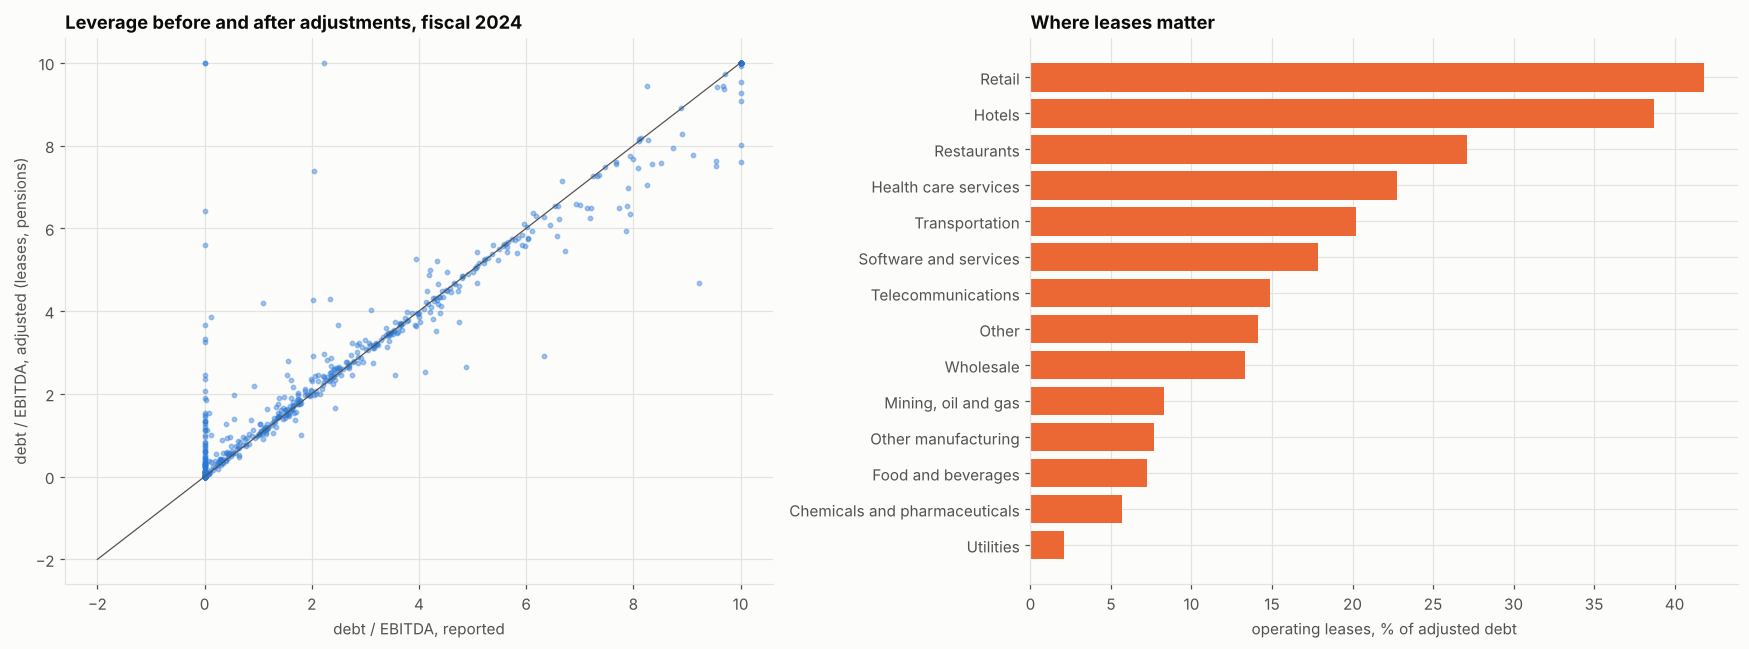

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
a = ax[0]
x = L["debt / EBITDA | reported"].clip(-2, 10)
y_ = L["debt / EBITDA | adjusted"].clip(-2, 10)
a.scatter(x, y_, s=8, alpha=0.4, color=PALETTE[0])
a.plot([-2, 10], [-2, 10], color=INK_2, lw=0.8)
a.set_xlabel("debt / EBITDA, reported")
a.set_ylabel("debt / EBITDA, adjusted (leases, pensions)")
a.set_title(f"Leverage before and after adjustments, fiscal {L.cy.iloc[0]}")
a = ax[1]
b = BYS.sort_values("lease_share_of_adjusted_debt")
a.barh(b.index, b.lease_share_of_adjusted_debt * 100, color=PALETTE[1])
a.set_xlabel("operating leases, % of adjusted debt")
a.set_title("Where leases matter")
fig.tight_layout()
save_fig(fig, "01_analyst_adjustments")
plt.show()

In [10]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Median debt / EBITDA by sector",
        "Rating notches lost from adjusting coverage",
    ),
)
dash.add_trace(
    go.Bar(
        x=BYS.index,
        y=BYS.debt_EBITDA_reported,
        name="reported",
        marker_color=PALETTE[0],
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=BYS.index,
        y=BYS.debt_EBITDA_adjusted,
        name="adjusted",
        marker_color=PALETTE[3],
    ),
    1,
    1,
)
n = L.notches.clip(-3, 6).value_counts().sort_index()
dash.add_trace(
    go.Bar(x=n.index, y=n.values, marker_color=PALETTE[1], showlegend=False),
    1,
    2,
)
dash.update_layout(
    height=550,
    width=1400,
    template="simple_white",
    barmode="group",
    title="Analyst adjustments for comparability",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 7. Reading the results and limitations

**Operating leases are the adjustment that matters.** In fiscal 2024, 82% of the 1,728 non-financial companies with revenue above USD 250 million report operating lease liabilities, and together they add 17% to reported debt. Median debt to EBITDA rises from 1.7 to 2.1 and debt to capital from 0.28 to 0.34. One company in five moves by more than ten percentiles in the leverage rankings.

The effect is concentrated where the business runs on leased space:

- **Retail:** median debt to EBITDA quadruples from 0.5 to 2.2, and leases are 42% of adjusted debt.
- **Hotels:** 3.4 → 4.5; **restaurants:** 2.3 → 4.3; health-care services and transportation also rise.
- **Little change:** utilities, which own their assets.

Among individual companies, Amazon's leases (USD 80 billion) exceed its reported debt, and MGM Resorts' debt to EBITDA goes from 2.7 to 6.8 once its casino leases are counted.

**The other adjustments are small in aggregate.**
- **LIFO:** only 4% of company-years report a LIFO reserve, worth USD 15 billion in total, concentrated in Deere, Kroger, LyondellBasell, Dollar General and Grainger. For them it lifts inventory by up to 40%, but it barely moves aggregate ratios.
- **Pensions:** pension deficits add only 0.1% to debt in this sample, because few filers tag the funded status at the consolidated level and many large plans are now fully funded.
- **Deferred taxes:** treating net deferred tax liabilities as equity moves USD 521 billion from liabilities to equity (63% of company-years carry one), which lowers debt-to-capital for capital-intensive companies, but return on equity barely changes (median 8.4% → 7.9%; rank correlation 0.998).

**Ratings move less than leverage.** For the roughly 700 companies that report interest expense, adding lease interest to both EBIT and interest lowers median coverage from 3.1 to 3.0. The synthetic rating is unchanged for 85% of companies and falls (usually by one notch) for 14%. **Eleven companies fall from investment grade to high yield**: these are where rating agencies' adjustments make a real difference to borrowing costs.

**The adjusted ratios explain risk only marginally better.** Predicting the next year's equity volatility of 1,680 companies, OLS with adjusted ratios reaches a cross-validated R² of 0.228 against 0.224 with reported ratios, and LightGBM 0.282 against 0.279. The direction is the expected one, but the gain is small: size and profitability explain most of what leverage can, and the market already sees leases in the footnotes, now on the balance sheet.

**Limitations.**
- **XBRL errors pass through:** BWX Technologies, for example, appears with USD 21 billion of lease liabilities, almost certainly a scaling error in its tagging, which turns its adjusted leverage into 47 × EBITDA. Extreme values are clipped in the models but not removed from the tables.
- **Simplified adjustments:** the lease interest uses the reported weighted-average discount rate; pension deficits use the funded status where tagged, without separating service cost; deferred taxes are reclassified in full, whereas analysts judge which part will reverse.
- **Synthetic ratings use coverage only:** real ratings weigh business risk, size and leverage too.
- **Volatility is a proxy for credit risk:** spreads or defaults would be the direct test.

In [11]:
SUMM.to_csv(OUT_DIR / "reported_vs_adjusted.csv")
BYS.to_csv(OUT_DIR / "adjustments_by_sector.csv")
MIG.to_csv(OUT_DIR / "rating_migration.csv")
VOL.to_csv(OUT_DIR / "volatility_models.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_analyst_adjustments.png, adjustments_by_sector.csv, dashboard.html, dashboard.png, rating_migration.csv, reported_vs_adjusted.csv, volatility_models.csv


## References

- U.S. Securities and Exchange Commission. XBRL frames API and Financial Statement Data Sets. https://www.sec.gov/edgar/sec-api-documentation
- Damodaran, A. Ratings, interest coverage ratios and default spread. https://pages.stern.nyu.edu/~adamodar/
- Yahoo Finance. Monthly prices. https://finance.yahoo.com/
- CFA Institute. *CFA Program Curriculum Level I*, Financial Statement Analysis: Inventories; Long-Term Liabilities and Equity; Income Taxes; Financial Analysis Techniques.
- Financial Accounting Standards Board. ASC 842 *Leases*; ASC 715 *Compensation—Retirement Benefits*; ASC 330 *Inventory*; ASC 740 *Income Taxes*.
- Moody's Investors Service (2018). Financial Statement Adjustments in the Analysis of Non-Financial Corporations.
- Merton, R. C. (1974). On the pricing of corporate debt: The risk structure of interest rates. *Journal of Finance*, 29(2), 449–470.
- Kraft, P. (2015). Rating agency adjustments to GAAP financial statements and their effect on ratings and credit spreads. *The Accounting Review*, 90(2), 641–674.